In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("start")


start


In [20]:
df=pd.read_csv(r"C:\Users\nidap\Desktop\main project\financial risk analysis using EDA\loan_train.csv")
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
0,540179,697401,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,...,11943.68,10000.00,1973.61,0.0,0.00,0.0,Sep-12,3536.63,Mar-14,0.0
1,585434,752191,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,...,15470.79,14000.00,1723.48,0.0,0.00,0.0,May-13,2603.31,Jan-16,0.0
2,457736,569298,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,...,10472.09,9475.00,997.09,0.0,0.00,0.0,May-11,5365.49,Aug-15,0.0
3,734349,930860,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,...,4425.26,4000.00,425.26,0.0,0.00,0.0,Jul-13,1336.22,May-15,0.0
4,1050080,1281522,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,...,2321.34,2004.17,306.88,0.0,10.29,0.0,Sep-13,110.54,May-16,0.0


In [4]:
print("Dataset shape:",df.shape)
print("dataset columns:",df.columns)
print("Dataset information:",df.info())
print("Dataset statistics:",df.describe())

Dataset shape: (27003, 47)
dataset columns: Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'url', 'desc', 'purpose', 'title', 'zip_code',
       'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
       'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record',
       'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
       'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'last_credit_pull_d', 'pub_rec_bankruptcies'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27003 entries, 0 to 27002
Data columns (total 47 columns):
 #   Column                   Non-Nu

In [21]:
print("null values:",df.isnull().sum())

null values: id                             0
member_id                      0
loan_amnt                      0
funded_amnt                    0
funded_amnt_inv                0
term                           0
int_rate                       0
installment                    0
grade                          0
sub_grade                      0
emp_title                   1682
emp_length                   730
home_ownership                 0
annual_inc                     0
verification_status            0
issue_d                        0
loan_status                    0
url                            0
desc                        8779
purpose                        0
title                          9
zip_code                       0
addr_state                     0
dti                            0
delinq_2yrs                    0
earliest_cr_line               0
inq_last_6mths                 0
mths_since_last_delinq     17395
mths_since_last_record     25065
open_acc                      

In [24]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

id                          0.00
member_id                   0.00
loan_amnt                   0.00
funded_amnt                 0.00
funded_amnt_inv             0.00
term                        0.00
int_rate                    0.00
installment                 0.00
grade                       0.00
sub_grade                   0.00
emp_title                   6.23
emp_length                  2.70
home_ownership              0.00
annual_inc                  0.00
verification_status         0.00
issue_d                     0.00
loan_status                 0.00
url                         0.00
desc                       32.51
purpose                     0.00
title                       0.03
zip_code                    0.00
addr_state                  0.00
dti                         0.00
delinq_2yrs                 0.00
earliest_cr_line            0.00
inq_last_6mths              0.00
mths_since_last_delinq     64.42
mths_since_last_record     92.82
open_acc                    0.00
pub_rec   

In [61]:
df.duplicated().sum()

np.int64(0)

In [6]:
df["loan_status"].value_counts()

loan_status
0    23026
1     3977
Name: count, dtype: int64

In [7]:

df = df.drop(columns=[
    "mths_since_last_record",
    "mths_since_last_delinq",
    "desc"
])


In [18]:
df.fillna("Unknown", inplace=True)

print("Remaining missing values:", df.isnull().sum())

Remaining missing values: id                         0
member_id                  0
loan_amnt                  0
funded_amnt                0
funded_amnt_inv            0
term                       0
int_rate                   0
installment                0
grade                      0
sub_grade                  0
emp_title                  0
emp_length                 0
home_ownership             0
annual_inc                 0
verification_status        0
issue_d                    0
loan_status                0
url                        0
purpose                    0
title                      0
zip_code                   0
addr_state                 0
dti                        0
delinq_2yrs                0
earliest_cr_line           0
inq_last_6mths             0
open_acc                   0
pub_rec                    0
revol_bal                  0
revol_util                 0
total_acc                  0
out_prncp                  0
out_prncp_inv              0
total_pymnt      

In [11]:
df["pub_rec_bankruptcies"] = pd.to_numeric(
    df["pub_rec_bankruptcies"],errors="coerce")
df["pub_rec_bankruptcies"] = df["pub_rec_bankruptcies"].fillna(
    df["pub_rec_bankruptcies"].median())
df["pub_rec_bankruptcies"]

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
26998    0.0
26999    1.0
27000    0.0
27001    0.0
27002    0.0
Name: pub_rec_bankruptcies, Length: 27003, dtype: float64

In [13]:
df["pub_rec_bankruptcies"].isnull().sum()

np.int64(0)

In [88]:
df.isnull().sum()

id                         0
member_id                  0
loan_amnt                  0
funded_amnt                0
funded_amnt_inv            0
term                       0
int_rate                   0
installment                0
grade                      0
sub_grade                  0
emp_title                  0
emp_length                 0
home_ownership             0
annual_inc                 0
verification_status        0
issue_d                    0
loan_status                0
url                        0
purpose                    0
title                      0
zip_code                   0
addr_state                 0
dti                        0
delinq_2yrs                0
earliest_cr_line           0
inq_last_6mths             0
open_acc                   0
pub_rec                    0
revol_bal                  0
revol_util                 0
total_acc                  0
out_prncp                  0
out_prncp_inv              0
total_pymnt                0
total_pymnt_in

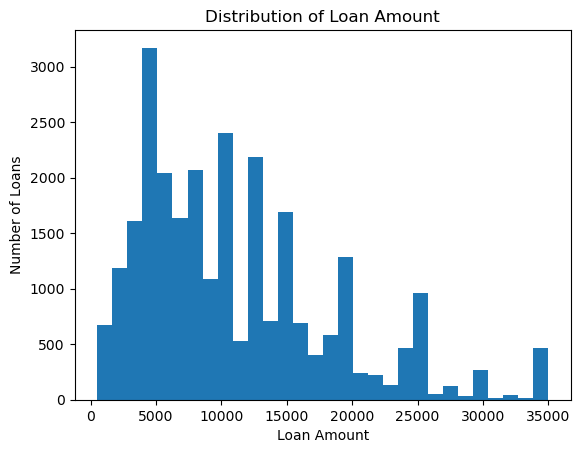

In [14]:
import matplotlib.pyplot as plt

plt.hist(df["loan_amnt"], bins=30)
plt.title("Distribution of Loan Amount")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Loans")
plt.show()

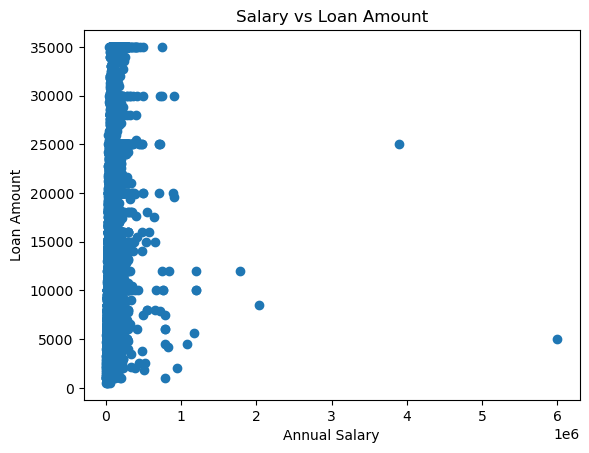

In [44]:
plt.scatter(df["annual_inc"], df["loan_amnt"])

plt.title("Salary vs Loan Amount")
plt.xlabel("Annual Salary")
plt.ylabel("Loan Amount")
plt.show()

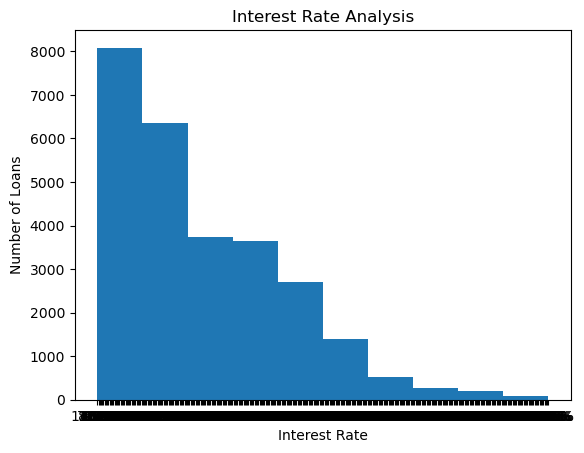

In [79]:
plt.hist(df["int_rate"])
plt.title("Interest Rate Analysis")
plt.xlabel("Interest Rate")
plt.ylabel("Number of Loans")
plt.show()

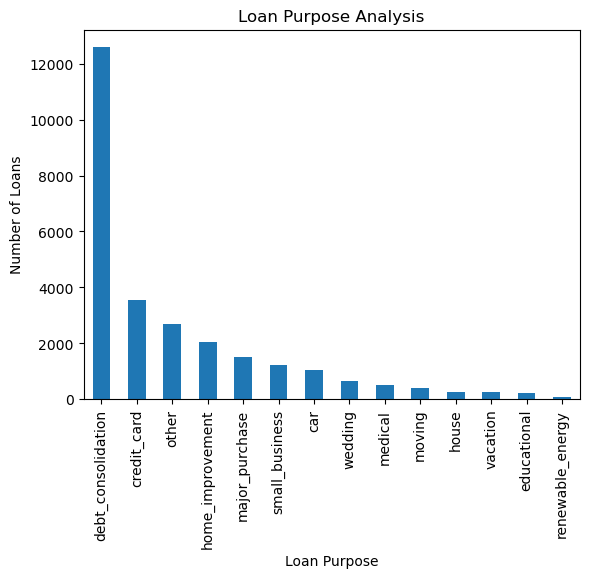

In [17]:
df["purpose"].value_counts().plot.bar()
plt.title("Loan Purpose Analysis")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Loans")
plt.show()

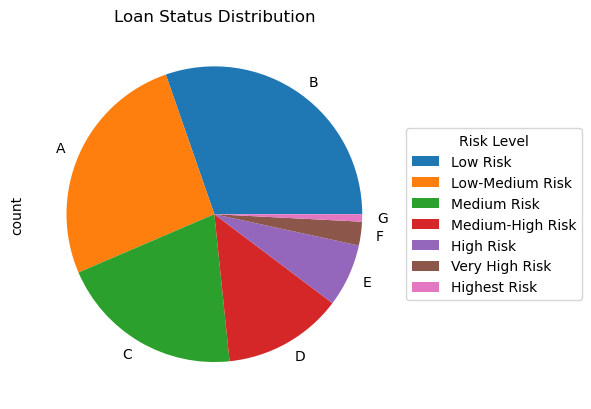

In [50]:
df["grade"].value_counts().plot.pie()

plt.title("Loan Status Distribution")
plt.legend(["Low Risk","Low-Medium Risk","Medium Risk","Medium-High Risk","High Risk ","Very High Risk ","Highest Risk "],
           title="Risk Level", loc="center left",bbox_to_anchor=(1, 0.5))
plt.show()

In [47]:
Q1 = df["loan_amnt"].quantile(0.25)
Q3 = df["loan_amnt"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[
    (df["loan_amnt"] < Q1 - 1.5 * IQR) |
    (df["loan_amnt"] > Q3 + 1.5 * IQR)]
print("Loan Amount Outliers:", len(outliers))

Loan Amount Outliers: 790


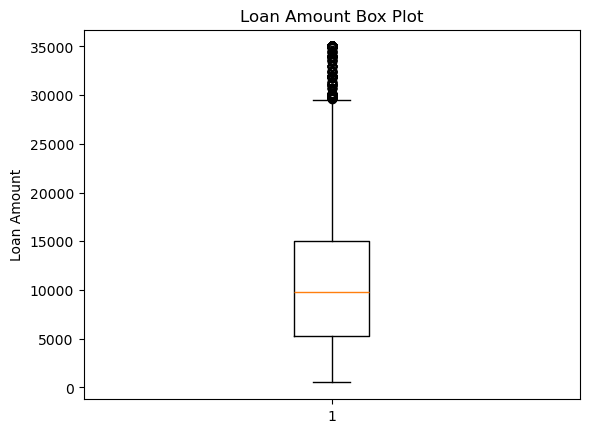

In [48]:
plt.boxplot(df["loan_amnt"])
plt.title("Loan Amount Box Plot")
plt.ylabel("Loan Amount")
plt.show()